# Identifikasi Wine Quality

| | |
|---|---|
| **Sumber** | https://www.kaggle.com/datasets/ruthgn/wine-quality-data-set-red-white-wine |
| **Ditempatkan di kategori** | Klasifikasi Biner |
| **Jenis klasifikasi sebenarnya** | Multikelas (skor kualitas 3 sampai 9) |
| **Status** | ❌ : bukan termasuk kategori ini |

## 1. Data Collecting

Dataset diambil dari Kaggle (link di tabel atas).

1. Download dataset dari Kaggle, lalu extract kalau berbentuk ZIP.
2. Taruh file data (`.csv` / `.xlsx`) di **folder yang sama dengan notebook ini**.
3. File data tidak ikut di-push ke GitHub karena sudah masuk `.gitignore`.

In [1]:
# Opsional: download otomatis (perlu `pip install kagglehub` dan login Kaggle)
# import kagglehub
# path = kagglehub.dataset_download("ruthgn/wine-quality-data-set-red-white-wine")
# print(path)

In [2]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Data Loading

In [3]:
FILES = sorted(glob.glob("*.csv") + glob.glob("*.xlsx"))
print("File data di folder ini:", FILES)
assert FILES, "Taruh file dataset (.csv / .xlsx) di folder yang sama dengan notebook ini"
DATA_PATH = FILES[0]   # ganti manual kalau ada lebih dari satu file
df = pd.read_excel(DATA_PATH) if DATA_PATH.endswith(".xlsx") else pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

File data di folder ini: ['wine-quality-white-and-red.csv']
Ukuran data (baris, kolom): (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 3. Identifikasi Jenis Klasifikasi

Notebook ini **tidak** membuat model. Tujuannya membuktikan lewat data bahwa dataset ini bukan **Klasifikasi Biner**.

Jumlah nilai unik target: 7
Nilai target: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


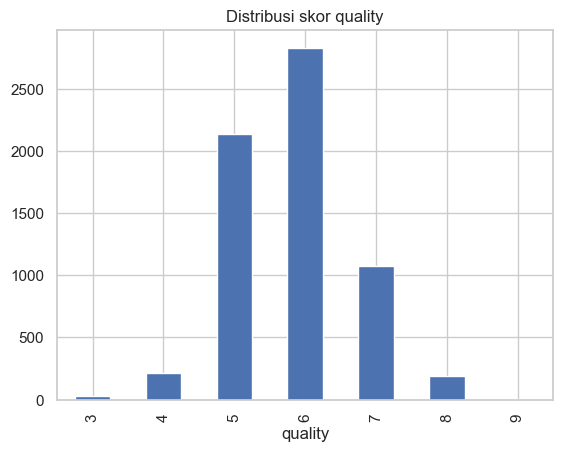


Contoh rekayasa (quality >= 6 dianggap bagus):
quality_biner
1    4113
0    2384
Name: count, dtype: int64


In [4]:
TARGET = "quality"   # sesuaikan jika nama kolom target berbeda
print("Jumlah nilai unik target:", df[TARGET].nunique())
print("Nilai target:", sorted(df[TARGET].unique()))
df[TARGET].value_counts().sort_index().plot(kind="bar")
plt.title("Distribusi skor quality"); plt.xlabel("quality"); plt.show()

# Wine sering "dibinerkan" dengan threshold. Itu rekayasa target, bukan bawaan dataset.
df["quality_biner"] = (df[TARGET] >= 6).astype(int)
print("\nContoh rekayasa (quality >= 6 dianggap bagus):")
print(df["quality_biner"].value_counts())

## 4. Kesimpulan


        Kolom target `quality` punya **lebih dari 2 nilai** (skor 3 sampai 9), jadi aslinya **multikelas** (ordinal), bukan biner.
        Dataset ini baru bisa dipakai sebagai biner kalau kita sendiri membuat threshold (misalnya `quality >= 6`). Itu hasil rekayasa target, bukan bawaan dataset.